In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

## Reviews

In [4]:
df_order_reviews = pd.read_csv('../data/raw/olist_order_reviews_dataset.csv')
df_order_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [5]:
df_order_reviews.shape

(99224, 7)

In [6]:
df_order_reviews.describe()

,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


In [7]:
# Mapeia condições de nulo (NaN) ou texto vazio/espaços
total_linhas = len(df_order_reviews)

is_empty_title = df_order_reviews['review_comment_title'].isna() | (df_order_reviews['review_comment_title'].astype(str).str.strip() == '')
is_empty_msg = df_order_reviews['review_comment_message'].isna() | (df_order_reviews['review_comment_message'].astype(str).str.strip() == '')

In [8]:
relatorio_nulos = pd.DataFrame({
    'Total de Linhas': [total_linhas, total_linhas],
    'Apenas NaN': [
        df_order_reviews['review_comment_title'].isna().sum(),
        df_order_reviews['review_comment_message'].isna().sum()
    ],
    'Apenas Texto Vazio ("")': [
        (df_order_reviews['review_comment_title'].notna() & (df_order_reviews['review_comment_title'].astype(str).str.strip() == '')).sum(),
        (df_order_reviews['review_comment_message'].notna() & (df_order_reviews['review_comment_message'].astype(str).str.strip() == '')).sum()
    ],
    'Total (NaN ou Vazio)': [is_empty_title.sum(), is_empty_msg.sum()],
    '% Nulos/Vazios': [
        (is_empty_title.sum() / total_linhas) * 100,
        (is_empty_msg.sum() / total_linhas) * 100
    ]
    }, index=['review_comment_title', 'review_comment_message'])

relatorio_nulos['% Nulos/Vazios'] = relatorio_nulos['% Nulos/Vazios'].map('{:.2f}%'.format)

relatorio_nulos

,Total de Linhas,Apenas NaN,"Apenas Texto Vazio ("""")",Total (NaN ou Vazio),% Nulos/Vazios
review_comment_title,99224,87656,2,87658,88.34%
review_comment_message,99224,58247,27,58274,58.73%


In [9]:
ambas_vazias_abs = (is_empty_title & is_empty_msg).sum()
ambas_vazias_pct = (ambas_vazias_abs / total_linhas) * 100

print("\n=== AMBAS AS COLUNAS NULAS/VAZIAS JUNTAS ===")
print(f"Quantidade Absoluta: {ambas_vazias_abs} registros")
print(f"Percentual:          {ambas_vazias_pct:.2f}% do total do DataFrame")


=== AMBAS AS COLUNAS NULAS/VAZIAS JUNTAS ===
Quantidade Absoluta: 56537 registros
Percentual:          56.98% do total do DataFrame


In [10]:
df_order_reviews['count_chars_reviews'] = (
    df_order_reviews['review_comment_message']
    .str.len()
    .fillna(0)
    .astype(int)
)

df_order_reviews['count_words_reviews'] = (
    df_order_reviews['review_comment_message']
    .str.split()
    .str.len()
    .fillna(0)
    .astype(int)
)

df_order_reviews

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,count_chars_reviews,count_words_reviews
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59,0,0
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13,0,0
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24,0,0
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06,37,6
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53,100,15
...,...,...,...,...,...,...,...,...,...
99219,574ed12dd733e5fa530cfd4bbf39d7c9,2a8c23fee101d4d5662fa670396eb8da,5,NaN,NaN,2018-07-07 00:00:00,2018-07-14 17:18:30,0,0
99220,f3897127253a9592a73be9bdfdf4ed7a,22ec9f0669f784db00fa86d035cf8602,5,NaN,NaN,2017-12-09 00:00:00,2017-12-11 20:06:42,0,0
99221,b3de70c89b1510c4cd3d0649fd302472,55d4004744368f5571d1f590031933e4,5,NaN,"Excelente mochila, entrega super rápida. Super...",2018-03-22 00:00:00,2018-03-23 09:10:43,67,9
99222,1adeb9d84d72fe4e337617733eb85149,7725825d039fc1f0ceb7635e3f7d9206,4,NaN,NaN,2018-07-01 00:00:00,2018-07-02 12:59:13,0,0


In [11]:
df_duplicadas_resumo = (
    df_order_reviews[df_order_reviews['review_comment_message'].notna()]
    .value_counts(subset=['review_comment_message'])
    .reset_index(name='total_repeticoes')
    .query('total_repeticoes > 1')
)

print("Total de reviews duplicadas:", df_duplicadas_resumo['total_repeticoes'].sum())

df_duplicadas_resumo

Total de reviews duplicadas: 6000


,review_comment_message,total_repeticoes
0,Muito bom,230
1,Bom,189
2,muito bom,122
3,bom,107
4,Recomendo,100
...,...,...
1177,Entrega super rápida,2
1178,"Ótimo, excelente, recomendo a todos",2
1179,Estou aguardando a encomenda. \r\nRecebi o avi...,2
1180,Super recomendo!!!!!,2


In [18]:
def plot_distribuicao_colunas(
    df, 
    colunas, 
    titulos=None, 
    bins=30, 
    cor='#4C8CBF', 
    figsize=None, 
    step_ticks=10, 
    filtrar_zeros=False
):
    """
    Gera gráficos de distribuição (Histograma e Boxplot) exibindo a porcentagem
    em relação ao total em cima de cada barra.
    """
    if isinstance(colunas, str):
        colunas = [colunas]

    num_cols = len(colunas)

    if titulos is None:
        titulos = [f"Distribuição de {col}" for col in colunas]
    elif len(titulos) != num_cols:
        raise ValueError("A quantidade de títulos deve ser igual à quantidade de colunas.")

    if figsize is None:
        figsize = (7 * num_cols, 8)

    fig, axes = plt.subplots(
        nrows=2, 
        ncols=num_cols, 
        figsize=figsize, 
        sharex=False,
        gridspec_kw={'height_ratios': [3, 1]}
    )

    if num_cols == 1:
        axes = [[axes[0]], [axes[1]]]

    for i, col in enumerate(colunas):
        dados = df[col].dropna()

        # Filtra os valores zerados caso solicitado
        if filtrar_zeros:
            dados = dados[dados > 0]

        if len(dados) == 0:
            continue

        total_registros = len(dados)
        v_min, v_max = int(dados.min()), int(dados.max())

        # Ajusta o intervalo dos marcadores do eixo X
        step = step_ticks if v_max > 50 else max(2, step_ticks // 2)
        ticks = np.arange(0, v_max + step, step)

        # 1. Histograma
        n, bins_edges, patches = axes[0][i].hist(
            dados, bins=bins, color=cor, edgecolor='white', alpha=0.9
        )
        axes[0][i].set_title(titulos[i], fontsize=12, fontweight='bold')
        axes[0][i].set_ylabel('Frequência', fontsize=10)
        axes[0][i].set_xlabel(col, fontsize=10, fontweight='bold')
        axes[0][i].set_xticks(ticks)
        axes[0][i].tick_params(axis='x', rotation=45)
        axes[0][i].grid(True, linestyle='--', alpha=0.5)

        # Adiciona o percentual no topo de cada barra
        max_y = max(n)
        for count, patch in zip(n, patches):
            if count > 0:
                pct = (count / total_registros) * 100
                x = patch.get_x() + patch.get_width() / 2
                y = patch.get_height()
                
                # Exibe o rótulo com rotação de 90° para não encavalar as porcentagens
                if pct >= 0.1:  # Ignora barras insignificantes (<0.1%)
                    axes[0][i].annotate(
                        f'{pct:.1f}%',
                        xy=(x, y),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha='center', va='bottom',
                        fontsize=8,
                        rotation=90
                    )

        # Aumenta o limite do Eixo Y em 18% para não cortar o texto do topo
        axes[0][i].set_ylim(0, max_y * 1.18)

        # 2. Boxplot
        axes[1][i].boxplot(
            dados, 
            vert=False, 
            patch_artist=True,
            boxprops=dict(facecolor=cor, color='black', alpha=0.9),
            medianprops=dict(color='red', linewidth=1.5),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black')
        )
        axes[1][i].set_xlabel(col, fontsize=10, fontweight='bold')
        axes[1][i].set_xticks(ticks)
        axes[1][i].tick_params(axis='x', rotation=45)
        axes[1][i].set_yticks([])
        axes[1][i].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

C:\Users\Shoiti\AppData\Local\Temp\ipykernel_16096\3602278913.py:91: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1][i].boxplot(
C:\Users\Shoiti\AppData\Local\Temp\ipykernel_16096\3602278913.py:91: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1][i].boxplot(


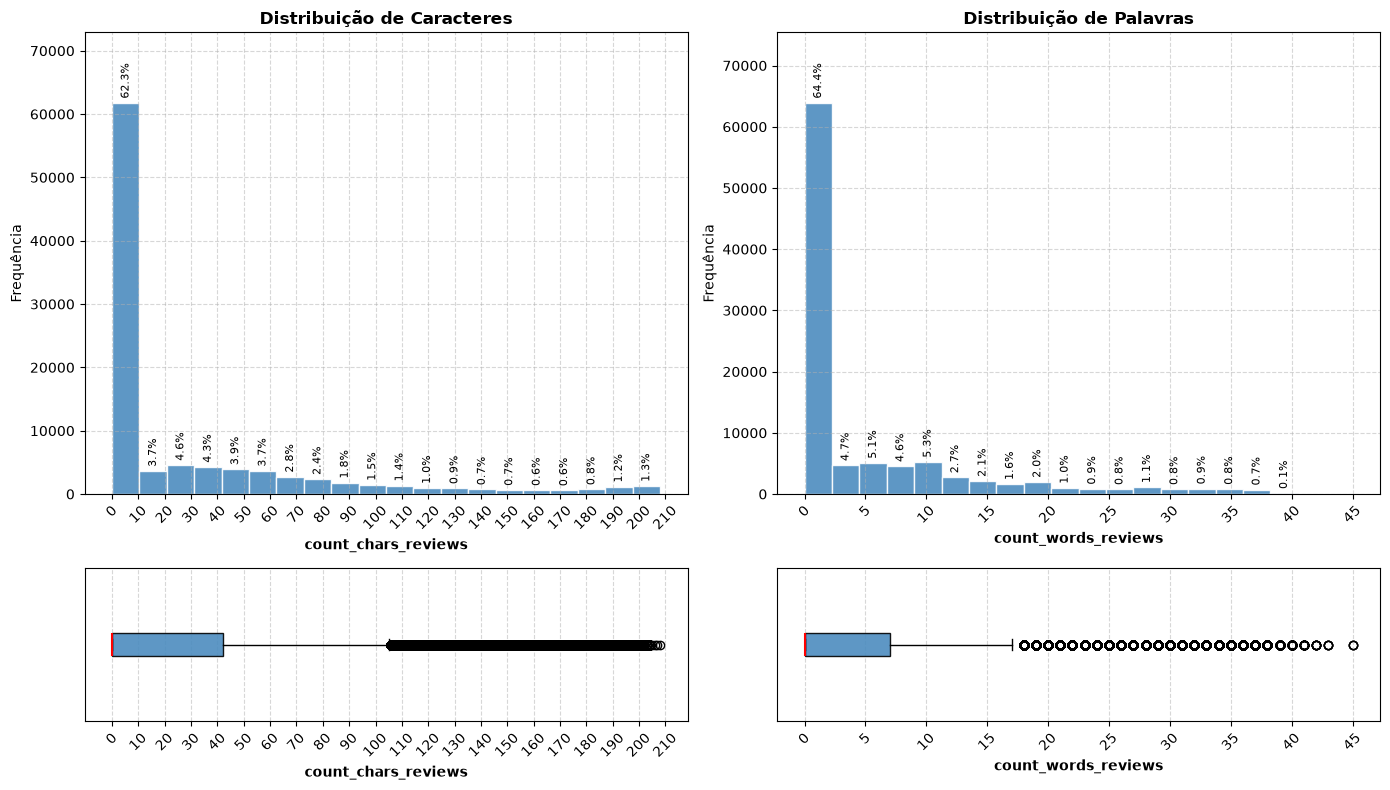

In [20]:
plot_distribuicao_colunas(
    df=df_order_reviews,
    colunas=['count_chars_reviews', 'count_words_reviews'],
    titulos=['Distribuição de Caracteres', 'Distribuição de Palavras'],
    bins=20,
    filtrar_zeros=False
)

C:\Users\Shoiti\AppData\Local\Temp\ipykernel_16096\3602278913.py:91: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1][i].boxplot(
C:\Users\Shoiti\AppData\Local\Temp\ipykernel_16096\3602278913.py:91: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1][i].boxplot(


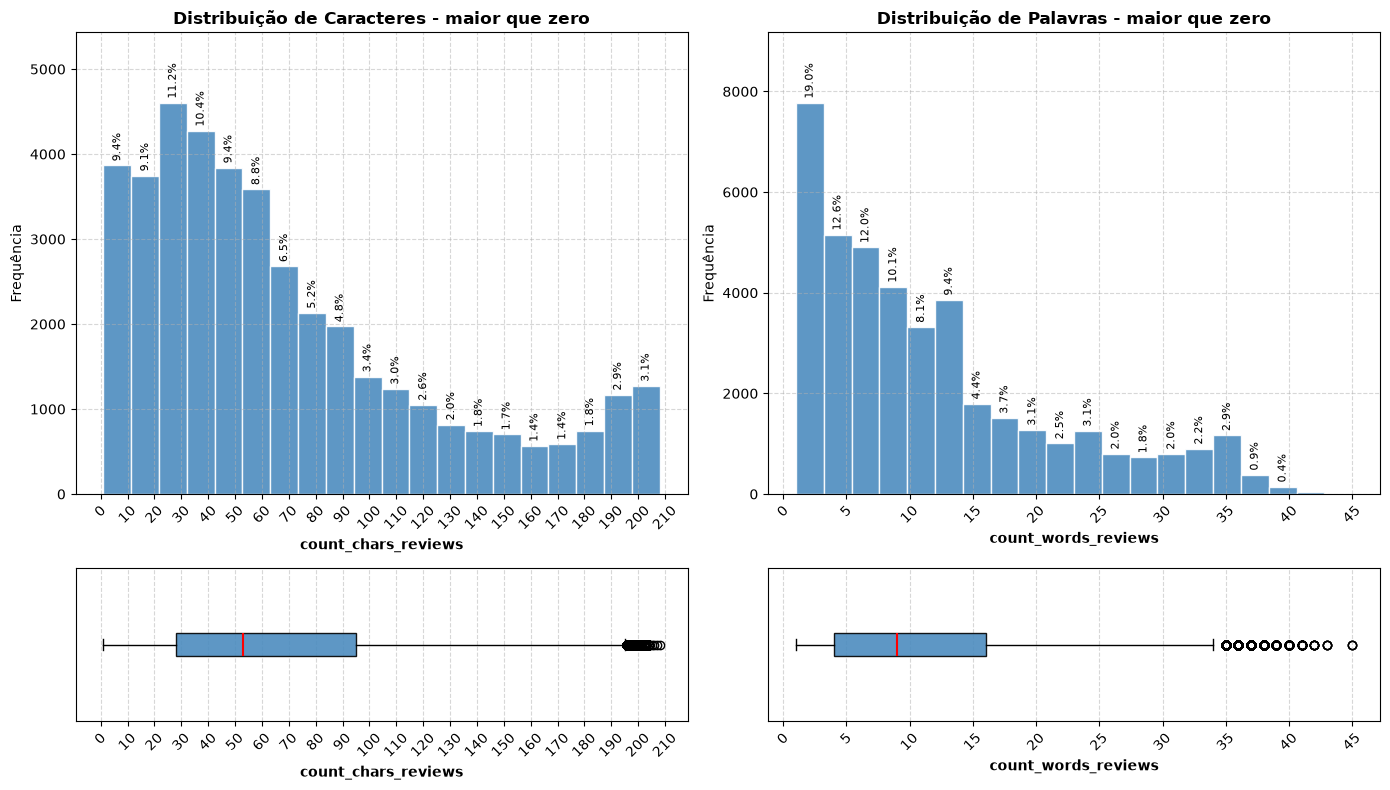

In [22]:
plot_distribuicao_colunas(
    df=df_order_reviews,
    colunas=['count_chars_reviews', 'count_words_reviews'],
    titulos=['Distribuição de Caracteres - maior que zero', 'Distribuição de Palavras - maior que zero'],
    bins=20,
    filtrar_zeros=True
)

C:\Users\Shoiti\AppData\Local\Temp\ipykernel_16096\3602278913.py:91: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1][i].boxplot(


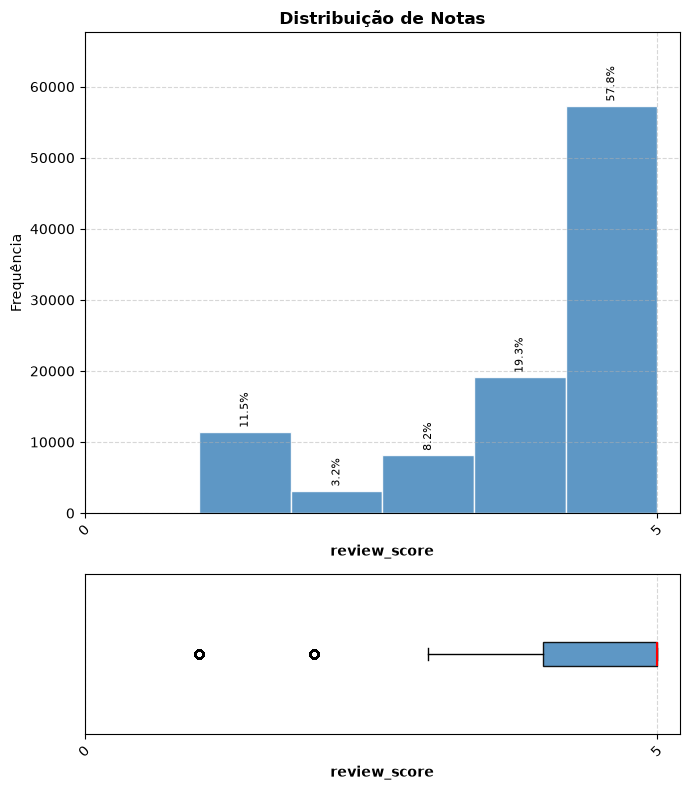

In [24]:
plot_distribuicao_colunas(
    df=df_order_reviews,
    colunas=['review_score'],
    titulos=['Distribuição de Notas'],
    bins=5
)

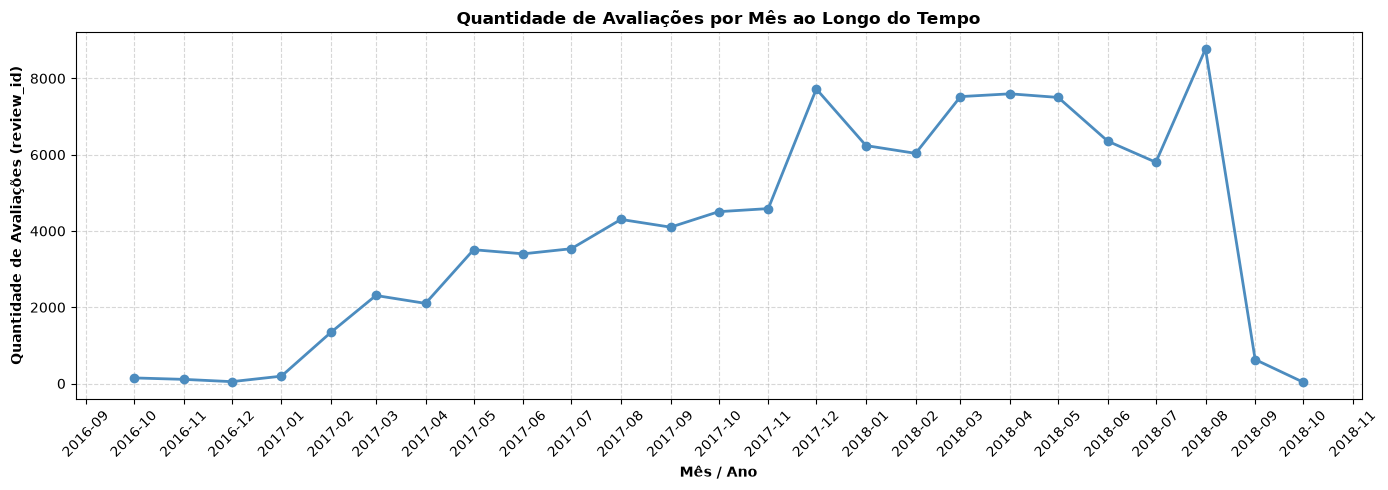

In [30]:
df_order_reviews['review_answer_timestamp'] = pd.to_datetime(df_order_reviews['review_answer_timestamp'])

df_mensal = (
    df_order_reviews
    .groupby(df_order_reviews['review_answer_timestamp'].dt.to_period('M'))['review_id']
    .nunique()
    .reset_index()
)

df_mensal['review_answer_timestamp'] = df_mensal['review_answer_timestamp'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df_mensal['review_answer_timestamp'], 
    df_mensal['review_id'], 
    marker='o', 
    color='#4C8CBF', 
    linewidth=2,
    markersize=6
)

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

ax.tick_params(axis='x', rotation=45)

# Títulos e estilo
ax.set_title('Quantidade de Avaliações por Mês ao Longo do Tempo', fontsize=12, fontweight='bold')
ax.set_xlabel('Mês / Ano', fontsize=10, fontweight='bold')
ax.set_ylabel('Quantidade de Avaliações (review_id)', fontsize=10, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [25]:
df_order_reviews

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,count_chars_reviews,count_words_reviews
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59,0,0
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13,0,0
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24,0,0
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06,37,6
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53,100,15
...,...,...,...,...,...,...,...,...,...
99219,574ed12dd733e5fa530cfd4bbf39d7c9,2a8c23fee101d4d5662fa670396eb8da,5,NaN,NaN,2018-07-07 00:00:00,2018-07-14 17:18:30,0,0
99220,f3897127253a9592a73be9bdfdf4ed7a,22ec9f0669f784db00fa86d035cf8602,5,NaN,NaN,2017-12-09 00:00:00,2017-12-11 20:06:42,0,0
99221,b3de70c89b1510c4cd3d0649fd302472,55d4004744368f5571d1f590031933e4,5,NaN,"Excelente mochila, entrega super rápida. Super...",2018-03-22 00:00:00,2018-03-23 09:10:43,67,9
99222,1adeb9d84d72fe4e337617733eb85149,7725825d039fc1f0ceb7635e3f7d9206,4,NaN,NaN,2018-07-01 00:00:00,2018-07-02 12:59:13,0,0
